In [2]:
## Use Data set of real pictures precropped nicely but from many decks to see if we can get better results

import torch
import torchvision

In [ ]:
## Get Data

from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader
from pathlib import Path
from torchvision import transforms




data_folder = Path(r"C:\Users\hartmawa\Music\Deep Learning\src\Project\Real_Card_Larger_Data")


transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# find training folder
train_dataset = ImageFolder(data_folder / "train", transform=transform)

ranks = ["A", "2", "3", "4", "5", "6", "7", "8", "9", "10"]

rank_mapping = {
    "ace": "A", "two": "2", "three": "3", "four": "4",
    "five": "5", "six": "6", "seven": "7", "eight": "8",
    "nine": "9", "ten": "10", "jack": "10", "queen": "10",
    "king": "10"
}

#Get labels from folder names
label_mapping = {index: ranks.index(rank_mapping[folder_name.split()[0].lower()])
    for index, folder_name in enumerate(train_dataset.classes)
    if folder_name.split()[0].lower() in rank_mapping}

#keep cards we wnat, remove joker
train_dataset.samples = [(path, label_mapping[label]) 
    for path, label 
    in train_dataset.samplesif label in label_mapping]

train_dataset.targets = [label for _, label in train_dataset.samples]
train_dataset.imgs = train_dataset.samples
train_dataset.classes = ranks
train_dataset.class_to_idx = {rank: index for index, rank in enumerate(ranks)}

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)


Training images: 7509


In [22]:
import torch
from pathlib import Path
from torch import nn
from torch.utils.data import DataLoader
from torchvision import models, transforms
from torchvision.datasets import ImageFolder

torch.manual_seed(42)

# Dataset location
data_folder = Path(r"C:\Users\hartmawa\Music\Deep Learning\src\Project\Real_Card_Larger_Data")

# Our 10 blackjack classes
ranks = ["A", "2", "3", "4", "5", "6", "7", "8", "9", "10"]

rank_mapping = {
    "ace": "A", "two": "2", "three": "3", "four": "4",
    "five": "5", "six": "6", "seven": "7", "eight": "8",
    "nine": "9", "ten": "10", "jack": "10", "queen": "10",
    "king": "10"
}

# Resize, convert to grayscale, and normalize.
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Load training and validation images.
train_dataset = ImageFolder(data_folder / "train", transform=transform)
val_dataset = ImageFolder(data_folder / "valid", transform=transform)

# Convert folder labels to our 10 classes and exclude jokers.
for dataset in [train_dataset, val_dataset]:
    label_mapping = {}

    for index, folder_name in enumerate(dataset.classes):
        first_word = folder_name.split()[0].lower()

        if first_word in ["joker", "jokers"]:
            continue

        if first_word not in rank_mapping:
            raise ValueError(f"Unrecognized class folder: {folder_name}")

        rank = rank_mapping[first_word]
        label_mapping[index] = ranks.index(rank)

    dataset.samples = [ (path, label_mapping[label])
        for path, label in dataset.samples
        if label in label_mapping]

    dataset.targets = [label for _, label in dataset.samples]
    dataset.imgs = dataset.samples
    dataset.classes = ranks.copy()
    dataset.class_to_idx = {rank: index for index, rank in enumerate(ranks)}

# Create batches
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=0)

val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=0)

#use GPU
device = torch.device("cuda")

# Load pretrained ResNet-18.
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Use pre trained resnet parameters
for parameter in model.parameters():
    parameter.requires_grad = False

#Make final 10 class layer for the cards
model.fc = nn.Linear(model.fc.in_features, len(ranks))
model = model.to(device)

#Set up loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.fc.parameters(), lr=0.001)


In [ ]:
## Train Model

num_epochs = 30

for epoch in range(num_epochs):
    model.eval()
    model.fc.train()


    # Initialize counters at zero
    total_loss = 0
    train_correct = 0
    train_total = 0

    for batch_index, (images, labels) in enumerate(train_loader):
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        train_correct += (outputs.argmax(dim=1) == labels).sum().item()
        train_total += labels.size(0)

        if (batch_index + 1) % 100 == 0:
            print(f"Epoch {epoch + 1}: "
                  f"batch {batch_index + 1}/{len(train_loader)}")

    model.eval()
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            val_correct += (outputs.argmax(dim=1) == labels).sum().item()
            val_total += labels.size(0)

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Loss: {total_loss / train_total:.4f} | "
        f"Train accuracy: {100 * train_correct / train_total:.1f}% | "
        f"Validation accuracy: {100 * val_correct / val_total:.1f}%"
    )

Epoch 1: batch 100/235
Epoch 1: batch 200/235
Epoch 1/10 | Loss: 1.1359 | Train accuracy: 64.5% | Validation accuracy: 65.4%
Epoch 2: batch 100/235
Epoch 2: batch 200/235
Epoch 2/10 | Loss: 1.0809 | Train accuracy: 66.5% | Validation accuracy: 70.8%
Epoch 3: batch 100/235
Epoch 3: batch 200/235
Epoch 3/10 | Loss: 1.0518 | Train accuracy: 67.7% | Validation accuracy: 69.2%
Epoch 4: batch 100/235
Epoch 4: batch 200/235
Epoch 4/10 | Loss: 1.0164 | Train accuracy: 68.6% | Validation accuracy: 71.2%
Epoch 5: batch 100/235
Epoch 5: batch 200/235
Epoch 5/10 | Loss: 0.9935 | Train accuracy: 69.6% | Validation accuracy: 70.4%
Epoch 6: batch 100/235
Epoch 6: batch 200/235
Epoch 6/10 | Loss: 0.9731 | Train accuracy: 69.6% | Validation accuracy: 69.6%
Epoch 7: batch 100/235
Epoch 7: batch 200/235
Epoch 7/10 | Loss: 0.9529 | Train accuracy: 70.7% | Validation accuracy: 70.0%
Epoch 8: batch 100/235
Epoch 8: batch 200/235
Epoch 8/10 | Loss: 0.9257 | Train accuracy: 71.4% | Validation accuracy: 70.0%


In [ ]:
## Save Model

from pathlib import Path

model_name="resnet18_realcard_combinedface"

save_path = Path.home() / "models" / f"{model_name}.pth"
save_path.parent.mkdir(parents=True, exist_ok=True)

torch.save({"model_state_dict": model.state_dict(),
    "ranks": ranks,
    "model_name": model_name
}, save_path)

Model saved to: C:\Users\hartmawa\models\resnet18_realcard_combinedface.pth


In [19]:
## Load in Real Photos of Cards

from PIL import Image, ImageOps

folder = Path(r"C:\Users\hartmawa\Music\Deep Learning\src\Project\Full_Deck_BW")

image_paths=sorted(path for path in folder.iterdir())

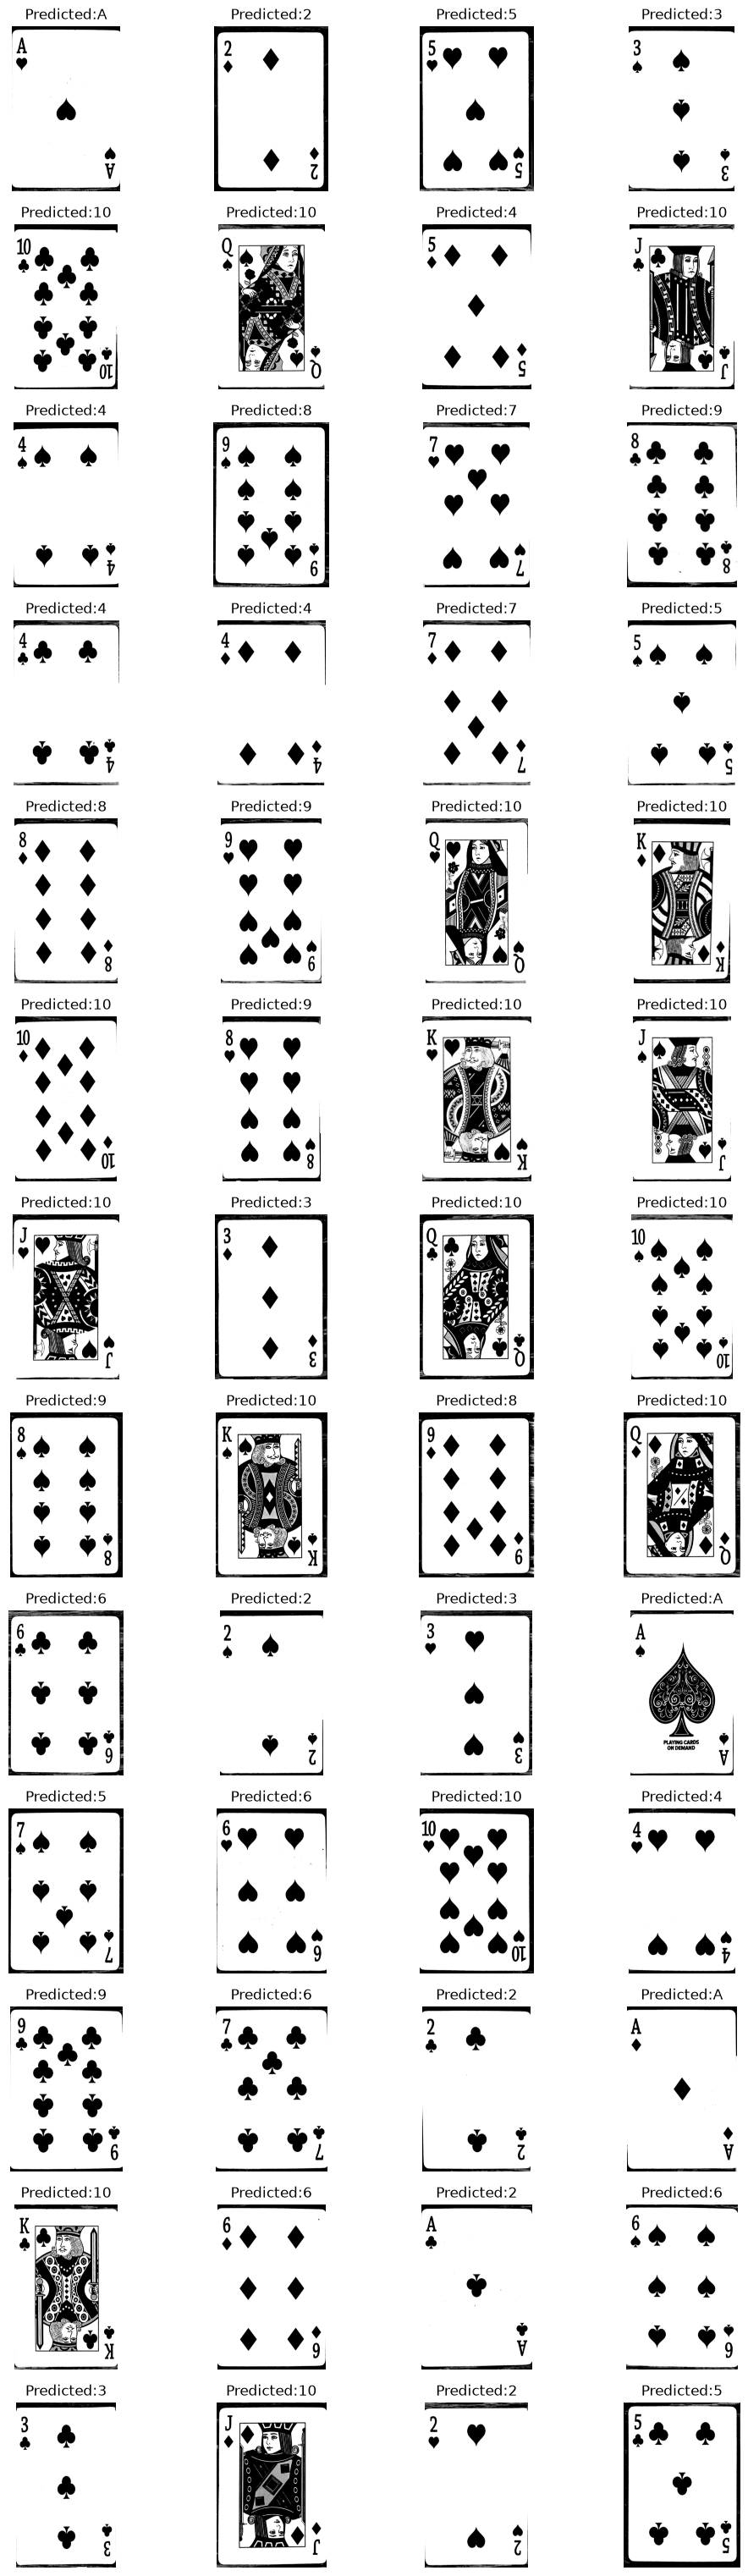

In [21]:
## Open Model and avaluate Pictures

import random
import torch
import matplotlib.pyplot as plt


model.eval() #Put model in evaluation mode

fig, axes = plt.subplots(13,4, figsize=(12,39))

for ax in axes.flat:
    ax.axis("off")

with torch.no_grad():
    for ax, path in zip(axes.flat, image_paths):
        image=ImageOps.exif_transpose(Image.open(path).convert("RGB")) #Make sure image is in RGB
        
        inputs=transform(image).unsqueeze(0).to(device) #Prepare image
        
        scores=model(inputs)#Run Model
        prediction=scores.argmax(dim=1).item()
        
        ax.imshow(image)
        ax.set_title(f"Predicted:{ranks[prediction]}")
        
plt.show()